# GS 2026.2 — Redes Neurais Artificiais — CitizenTech

**Integrantes (nome completo + RM):** [HUMANO — preencher]

- **Problema CitizenTech:** Estimação de demanda futura de admissões formais de nível superior em ocupações tecnológicas, como subsídio informacional para profissionais graduados em transição de carreira.
- **Público:** Profissionais com ensino superior completo em processo de requalificação profissional para o setor de tecnologia.
- **Contexto da Aplicação:** Plataforma de inteligência territorial que reduz a assimetria informativa no mercado de trabalho formal, integrando dados oficiais do Novo Caged (MTE).
- **Objetivo da Rede Neural:** Processar padrões temporais multivariados e interações não-lineares entre ocupações e territórios para prever o total de admissões formais no trimestre seguinte ($t+1$ a $t+3$).

## 1. Problema e Aplicação
- **Problema CitizenTech:** A transição de carreira para a área de tecnologia é marcada por incertezas quanto à demanda real do mercado. Profissionais graduados frequentemente baseiam suas decisões de capacitação em percepções distorcidas de marketing.
- **Público Impactado e Contexto:** Graduados em busca de transição profissional que necessitam de métricas realistas e territorializadas de absorção no emprego formal para planejar seus estudos e escolhas de carreira.
- **Como a Rede Neural Contribui:** A rede neural processa conjuntamente o histórico de admissões, desligamentos e variáveis territoriais para estimar a absorção formal futura, capturando correlações complexas entre estados e ocupações.
- **Entradas do Modelo:** 14 features numéricas normalizadas (admissões, desligamentos, lags 1, 2, 3 e 12, médias e somas móveis de 3 meses, indicadores sazonais e mês calendário) somadas a 38 colunas one-hot (3 destinos ocupacionais + 27 UFs + indicadores de ausência), totalizando dimensão de entrada = 52.
- **Saída Esperada:** Valor contínuo estimando as admissões formais acumuladas no trimestre móvel seguinte ($A(t+1) + A(t+2) + A(t+3)$).

In [1]:
import hashlib
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

import citizentech_ml

_ = citizentech_ml.__file__

# Raiz do repositório
caminho_atual = Path(os.getcwd()).resolve()
while caminho_atual != caminho_atual.parent:
    if (caminho_atual / "05_ML").exists() and (caminho_atual / "07_RedesNeurais").exists():
        REPO_ROOT = caminho_atual
        break
    caminho_atual = caminho_atual.parent
else:
    REPO_ROOT = Path(os.getcwd()).resolve()

DIR_FIGURAS_RNA = REPO_ROOT / "07_RedesNeurais" / "evidencias" / "figuras"
DIR_FIGURAS_RNA.mkdir(parents=True, exist_ok=True)

# 2. Dataset — Carga, Integridade e Amostra dos Dados declarados
dados_dir = os.environ.get("CITIZENTECH_DADOS")
if not dados_dir:
    raise ValueError("Variável de ambiente CITIZENTECH_DADOS não definida.")

caminho_painel = os.path.join(
    dados_dir, "caged", "painel", "r29_20261115_2041", "painel_mvp.parquet"
)
dir_classicos = os.path.join(dados_dir, "artefatos", "classicos", "20261115_r29_aceite")
dir_rna = os.path.join(dados_dir, "artefatos", "rna", "20261115_r29_aceite")

with open(caminho_painel, "rb") as f:
    sha256_painel = hashlib.sha256(f.read()).hexdigest()

assert sha256_painel == (
    "33a898980916c841c325fb9e37b643484ee1d6f8b7017a19f52208de02e922c5"
), f"Hash SHA-256 divergente: {sha256_painel}"

df = pd.read_parquet(caminho_painel)
assert df["competencia"].max() < "202601", (
    f"Competência máxima proibida encontrada: {df['competencia'].max()}"
)

print("=== DATASET NOVO CAGED / MTE (PAINEL MVP R29) ===")
print(f"Total de registros: {len(df)}")
print(f"Competências: {df['competencia'].min()} a {df['competencia'].max()}")
print(f"Colunas: {len(df.columns)}")
print("\nAmostra de 5 linhas do dataset:")
cols_exemplo = [
    "competencia", "destino", "uf", "admissoes", "desligamentos",
    "admissoes_lag_1", "admissoes_soma_3m", "alvo"
]
print(df[cols_exemplo].head(5).to_string(index=False))

=== DATASET NOVO CAGED / MTE (PAINEL MVP R29) ===
Total de registros: 5589
Competências: 202001 a 202509
Colunas: 32

Amostra de 5 linhas do dataset:
competencia           destino uf  admissoes  desligamentos  admissoes_lag_1  admissoes_soma_3m  alvo
     202001 analista_dados_bi 11        1.0            1.0              NaN                NaN   3.0
     202001 analista_dados_bi 12        0.0            0.0              NaN                NaN   0.0
     202001 analista_dados_bi 13        2.0            4.0              NaN                NaN   7.0
     202001 analista_dados_bi 14        0.0            0.0              NaN                NaN   0.0
     202001 analista_dados_bi 15        7.0            3.0              NaN                NaN  16.0


## 2. Dataset
- **Fonte Oficial:** Os dados são provenientes dos microdados administrativos oficiais do Novo Caged (Ministério do Trabalho e Emprego — MTE), gerados a partir das declarações obrigatórias do eSocial pelas empresas formais do Brasil.
- **Características:** Granularidade mensal cobrindo 27 UFs e 3 ocupações do recorte MVP de tecnologia (`analista_dados_bi`, `analista_monitoramento_iot`, `analista_processos`), restrito a trabalhadores com nível superior completo ou pós-graduação.
- **Por que a base é adequada?** O Caged constitui o censo exaustivo do emprego com carteira assinada no país, eliminando o viés amostral de pesquisas domiciliares e fornecendo registros empíricos confiáveis para treinamento de redes neurais.

In [2]:
# 3. Preparação dos Dados — Split Temporal, Embargos e Elegibilidade D04a
from citizentech_ml.features.densidade import calcular_densidade_treino

df_treino = df[df["particao"] == "treino"].copy()
dens = calcular_densidade_treino(df_treino)
elegiveis_set = set(
    zip(
        dens.loc[dens["elegivel"], "destino"],
        dens.loc[dens["elegivel"], "uf"],
        strict=False,
    )
)

df_val = df[df["particao"] == "validacao"].copy()
mask_val_eleg = df_val.apply(lambda r: (r["destino"], r["uf"]) in elegiveis_set, axis=1)
df_val_eleg = df_val[mask_val_eleg]

print(f"Séries Elegíveis (D04a - média treino >= 10): {len(elegiveis_set)} de 81")
print(
    f"Observações de validação externa em séries elegíveis: {len(df_val_eleg)} "
    "(55 séries x 9 meses)"
)

print("\nDivisão dos Dados e Protocolo de Embargo:")
print(" - Histórico Base (Lags): 202001 a 202012")
print(" - Treino Global (Fit): 202101 a 202409 (45 competências mensais)")
print(
    " - Embargo Externo: 202410 a 202412 "
    "(3 meses de proteção contra vazamento do alvo t+1..t+3)"
)
print(
    " - Validação Externa: 202501 a 202509 "
    "(9 competências mensais x 55 séries = 495 observações)"
)
print(" - Holdout 2026: estritamente fechado para avaliação cega")

Séries Elegíveis (D04a - média treino >= 10): 55 de 81
Observações de validação externa em séries elegíveis: 495 (55 séries x 9 meses)

Divisão dos Dados e Protocolo de Embargo:
 - Histórico Base (Lags): 202001 a 202012
 - Treino Global (Fit): 202101 a 202409 (45 competências mensais)
 - Embargo Externo: 202410 a 202412 (3 meses de proteção contra vazamento do alvo t+1..t+3)
 - Validação Externa: 202501 a 202509 (9 competências mensais x 55 séries = 495 observações)
 - Holdout 2026: estritamente fechado para avaliação cega


## 3. Preparação dos Dados
- **Embargo Interno e Externo:** Como a variável dependente é calculada como o somatório das admissões nos 3 meses subsequentes ($t+1$, $t+2$ e $t+3$), qualquer janela de teste imediatamente subsequente a uma janela de treino conteria observações que compartilham meses do alvo. A inclusão de um embargo temporal obrigatório de 3 meses elimina totalmente esse risco de vazamento temporal.
- **Padronização:** A padronização das features (subtração da média e divisão pelo desvio padrão) e a transformação de escala do alvo são ajustadas exclusivamente nos dados de treino.

In [3]:
# 4. Arquitetura da Rede Neural — Inspeção e Parâmetros da MLP Carregada
from citizentech_ml.rede_neural import carregar_modelo_rna

modelo_rna, prep_rna, man_rna = carregar_modelo_rna(dir_rna)

print("=== ARQUITETURA DO MODELO CARREGADO (MLP) ===")
print(modelo_rna)

total_params = sum(p.numel() for p in modelo_rna.parameters())
trainable_params = sum(p.numel() for p in modelo_rna.parameters() if p.requires_grad)

print(f"\nDimensão de Entrada: {prep_rna.dimensao_entrada}")
print(f"Total de Parâmetros: {total_params}")
print(f"Parâmetros Treináveis: {trainable_params}")
print(f"Configuração do Modelo: {man_rna['melhor_config']['params']}")

=== ARQUITETURA DO MODELO CARREGADO (MLP) ===
MLPRegressor(
  (rede): Sequential(
    (0): Linear(in_features=52, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)

Dimensão de Entrada: 52
Total de Parâmetros: 5505
Parâmetros Treináveis: 5505
Configuração do Modelo: {'nome': 'A', 'hidden_layers': [64, 32], 'dropout': 0.1, 'lr': 0.001, 'batch_size': 128}


## 4. Arquitetura da Rede Neural
- **Por que MLP e não CNN ou RNN?**
  1. *CNNs* foram desenvolvidas para dados com invariância por translação espacial (imagens, espectrogramas), não sendo aplicáveis a matrizes tabulares com features heterogêneas.
  2. *RNNs/LSTMs* modelam sequências temporais passo a passo, mas sofrem em séries temporais agregadas onde o histórico recente é compactado em lags explícitos (lag 1, 2, 3, 12, médias e somas móveis).
  3. A *Multi-Layer Perceptron (MLP)* é a arquitetura ideal para dados tabulares multivariados com lags engineered, permitindo que cada neurônio combine não-linearmente variáveis autorregressivas, indicadores de território e atributos ocupacionais.
- **Fluxo de Processamento:**
  A camada de entrada recebe o vetor de dimensão 52. Os sinais passam pela primeira camada densa ($52 	o 64$), ativação ReLU e Dropout (0,1), seguida da segunda camada ($64 	o 32$), ativação ReLU e Dropout, projetando finalmente na camada linear de saída ($32 	o 1$).

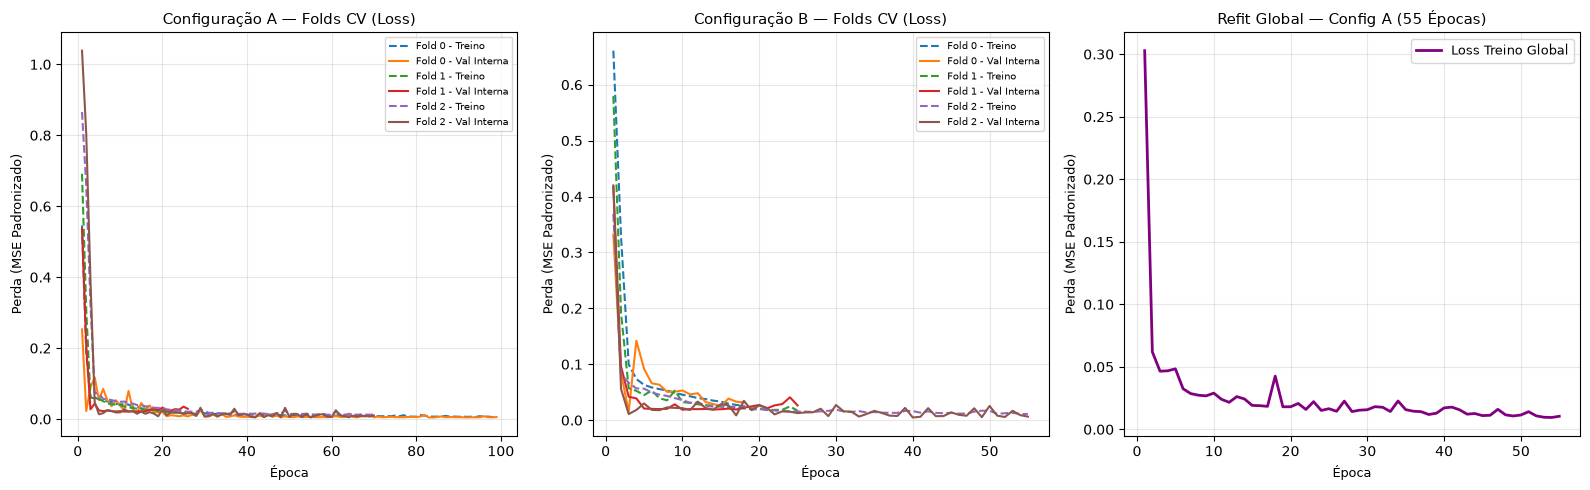

Parâmetros de treinamento da Configuração A:
 - Hidden layers: [64, 32]
 - Dropout: 0.1
 - Learning rate: 0.001 (Adam)
 - Batch size: 128
 - Épocas do refit global: 55


In [4]:
# 5. Treinamento — Curvas de Perda (Fit vs Validação Interna) e Refit Global
curvas = pd.read_csv(os.path.join(dir_rna, "curvas.csv"))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Config A folds
for fld in [0, 1, 2]:
    sub = curvas[(curvas["config"] == "A") & (curvas["fold"] == fld)]
    axes[0].plot(sub["epoca"], sub["loss_fit"], label=f"Fold {fld} - Treino", linestyle="--")
    axes[0].plot(
    sub["epoca"], sub["loss_val_interna"], label=f"Fold {fld} - Val Interna", linewidth=1.5
)

axes[0].set_title("Configuração A — Folds CV (Loss)", fontsize=11)
axes[0].set_xlabel("Época", fontsize=9)
axes[0].set_ylabel("Perda (MSE Padronizado)", fontsize=9)
axes[0].legend(fontsize=7)
axes[0].grid(True, alpha=0.3)

# Config B folds
for fld in [0, 1, 2]:
    sub = curvas[(curvas["config"] == "B") & (curvas["fold"] == fld)]
    axes[1].plot(sub["epoca"], sub["loss_fit"], label=f"Fold {fld} - Treino", linestyle="--")
    axes[1].plot(
    sub["epoca"], sub["loss_val_interna"], label=f"Fold {fld} - Val Interna", linewidth=1.5
)

axes[1].set_title("Configuração B — Folds CV (Loss)", fontsize=11)
axes[1].set_xlabel("Época", fontsize=9)
axes[1].set_ylabel("Perda (MSE Padronizado)", fontsize=9)
axes[1].legend(fontsize=7)
axes[1].grid(True, alpha=0.3)

# Refit Global Config A
sub_refit = curvas[curvas["config"] == "A_refit_global"]
axes[2].plot(
    sub_refit["epoca"],
    sub_refit["loss_fit"],
    color="purple",
    linewidth=2,
    label="Loss Treino Global",
)
axes[2].set_title("Refit Global — Config A (55 Épocas)", fontsize=11)
axes[2].set_xlabel("Época", fontsize=9)
axes[2].set_ylabel("Perda (MSE Padronizado)", fontsize=9)
axes[2].legend(fontsize=9)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(DIR_FIGURAS_RNA / "curvas_treinamento_rna.png", dpi=100)
plt.show()

print("Parâmetros de treinamento da Configuração A:")
print(" - Hidden layers: [64, 32]")
print(" - Dropout: 0.1")
print(" - Learning rate: 0.001 (Adam)")
print(" - Batch size: 128")
print(" - Épocas do refit global: 55")

## 5. Treinamento do Modelo
Os gráficos de perda demonstram:
1. **Convergência Estável:** A função de perda (MSE do alvo padronizado) decresce suavemente nas primeiras 20 épocas, estabilizando sem divergências ou oscilações caóticas.
2. **Early Stopping com Embargo:** Na validação cruzada, a paciência de 15 épocas e `min_delta = 1e-5` evitaram sobreajuste nos folds.
3. **Refit Global:** Após a seleção da Configuração A, o modelo final foi re-treinado sobre todo o período de treino (202101 a 202409) por 55 épocas (`num_epochs_refit = 55`), número determinado pela mediana de épocas ótimas dos folds do CV.

In [5]:
# 6. Refinamento e Otimização — Comparação das Configurações A e B
configs = man_rna["configs_detalhes"]

tabela_comp = []
for nome in ["A", "B"]:
    c = configs[nome]
    p = c["params"]
    tabela_comp.append({
        "Configuração": nome,
        "Camadas": str(p["hidden_layers"]),
        "Dropout": p["dropout"],
        "Learning Rate": p["lr"],
        "Batch Size": p["batch_size"],
        "MAE Médio CV": c["mae_medio"],
        "MAE Desvio": c["mae_desvio"],
        "WAPE Médio CV (%)": c["wape_medio"] * 100,
        "WAPE Desvio (%)": c["wape_desvio"] * 100,
        "MASE Médio CV": c["mase_medio"],
        "Tempo (s)": c["tempo_segundos"],
    })

df_comp = pd.DataFrame(tabela_comp)
print("=== COMPARAÇÃO DE CONFIGURAÇÕES NA VALIDAÇÃO CRUZADA ===")
print(df_comp.to_string(index=False))

=== COMPARAÇÃO DE CONFIGURAÇÕES NA VALIDAÇÃO CRUZADA ===
Configuração   Camadas  Dropout  Learning Rate  Batch Size  MAE Médio CV  MAE Desvio  WAPE Médio CV (%)  WAPE Desvio (%)  MASE Médio CV  Tempo (s)
           A  [64, 32]      0.1         0.0010         128     32.698283    8.423877          12.085891         3.342498       1.136107  29.629981
           B [128, 64]      0.2         0.0005         128     42.256961    8.481323          15.574079         3.142348       1.334630   6.208407


## 6. Refinamento e Otimização
- **Configuração A ([64, 32], dropout 0,1, lr 0,001):** Obteve MAE médio de 32,70 (+/- 8,42), WAPE médio de 12,09% e MASE de 1,14.
- **Configuração B ([128, 64], dropout 0,2, lr 0,0005):** Apresentou MAE médio de 42,26 (+/- 8,48), WAPE médio de 15,57% e MASE de 1,33.
- **Justificativa da Escolha da Configuração A:** A arquitetura mais compacta [64, 32] com menor taxa de dropout superou a rede maior [128, 64] em todas as métricas, demonstrando melhor generalização e menor risco de sobreparametrização.
- **Alerta sobre Viés de Seleção:** Ressalta-se que o CV não aninhado é uma métrica de seleção otimista; portanto, a comprovação final de generalização requer a avaliação no conjunto de validação externa e no holdout de 2026.

=== DESEMPENHO NA VALIDAÇÃO EXTERNA 2025 (495 LINHAS) ===
               Modelo       MAE       RMSE  WAPE (%)     MASE
Baseline Persistência 35.452525 103.582973 12.558772 0.798172
     Baseline Sazonal 33.595960  91.383795 11.901099 0.833493
     Ridge Regression 34.257654  84.418880 12.135499 1.220212
  MLP A (Rede Neural) 31.654461  73.672010 11.213338 1.135654

Contagem de previsões negativas: 0
Menor previsão negativa: None


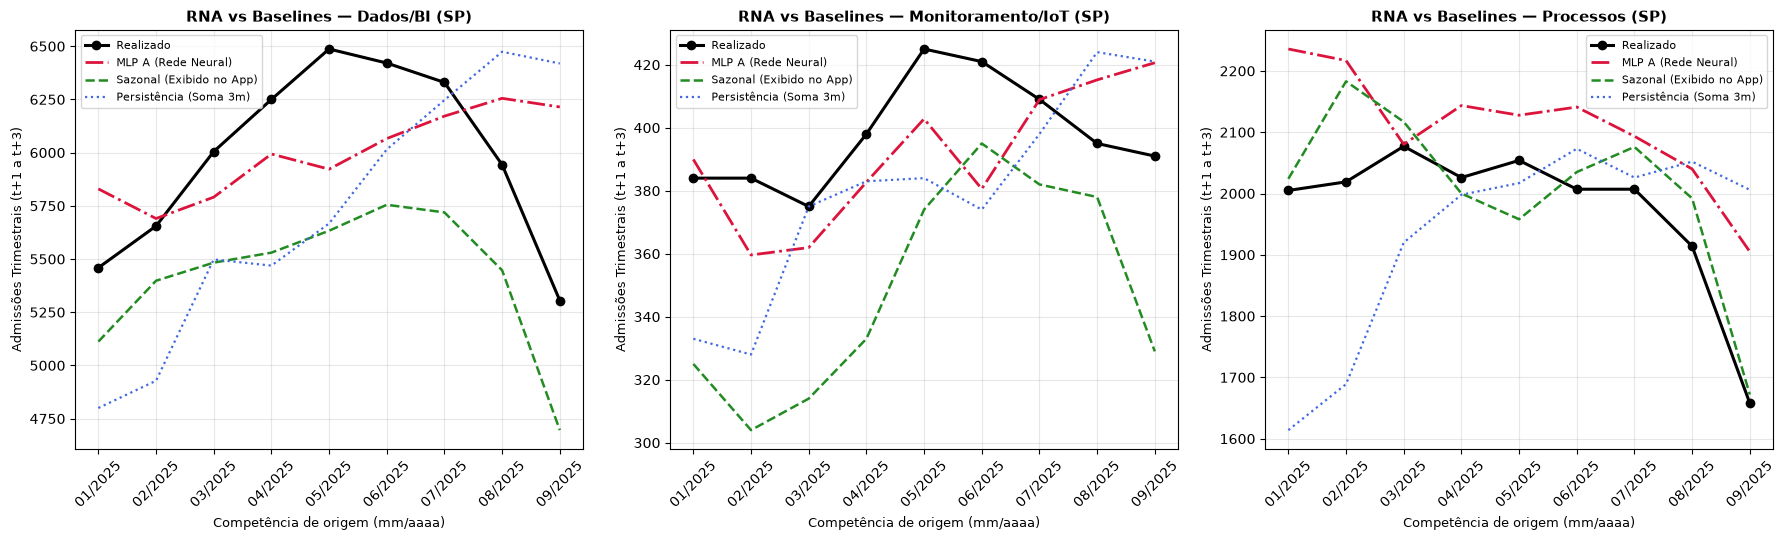

In [6]:
# 7. Avaliação dos Resultados — Validação Externa 2025 e Comparação com Baselines
from citizentech_ml.treinar_classicos import carregar_artefatos_classicos

art_c = carregar_artefatos_classicos(dir_classicos)
val_c = art_c["relatorio"]["validacao_externa"]
val_r = man_rna["validacao_externa"]

tabela_val = [
    {
        "Modelo": "Baseline Persistência",
        "MAE": val_c["baselines"]["persistencia"]["mae"],
        "RMSE": val_c["baselines"]["persistencia"]["rmse"],
        "WAPE (%)": val_c["baselines"]["persistencia"]["wape"] * 100,
        "MASE": val_c["baselines"]["persistencia"]["mase"],
    },
    {
        "Modelo": "Baseline Sazonal",
        "MAE": val_c["baselines"]["sazonal"]["mae"],
        "RMSE": val_c["baselines"]["sazonal"]["rmse"],
        "WAPE (%)": val_c["baselines"]["sazonal"]["wape"] * 100,
        "MASE": val_c["baselines"]["sazonal"]["mase"],
    },
    {
        "Modelo": "Ridge Regression",
        "MAE": val_c["modelos"]["ridge"]["mae"],
        "RMSE": val_c["modelos"]["ridge"]["rmse"],
        "WAPE (%)": val_c["modelos"]["ridge"]["wape"] * 100,
        "MASE": val_c["modelos"]["ridge"]["mase"],
    },
    {
        "Modelo": "MLP A (Rede Neural)",
        "MAE": val_r["mae"],
        "RMSE": val_r["rmse"],
        "WAPE (%)": val_r["wape"] * 100,
        "MASE": val_r["mase"],
    },
]

df_val_res = pd.DataFrame(tabela_val)
print("=== DESEMPENHO NA VALIDAÇÃO EXTERNA 2025 (495 LINHAS) ===")
print(df_val_res.to_string(index=False))

# Verificação de integridade: previsões negativas
print(f"\nContagem de previsões negativas: {man_rna['contagem_negativos']}")
print(f"Menor previsão negativa: {man_rna['min_previsao_negativa']}")
assert man_rna["contagem_negativos"] == 0

# Gráfico Real vs Previsto da RNA em SP
prev_r = pd.read_parquet(os.path.join(dir_rna, "previsoes.parquet"))
prev_val_r = prev_r[prev_r["modelo"] == "MLP_A_global_validacao"].copy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
destinos = ["analista_dados_bi", "analista_monitoramento_iot", "analista_processos"]
titulos = ["Dados/BI", "Monitoramento/IoT", "Processos"]

for i, (dest, tit) in enumerate(zip(destinos, titulos, strict=False)):
    sub_r = prev_val_r[
        (prev_val_r["uf"] == "35") & (prev_val_r["destino"] == dest)
    ].sort_values("competencia")
    sub_p = df[
        (df["uf"] == "35") & (df["destino"] == dest) & (df["particao"] == "validacao")
    ].sort_values("competencia")

    comps = sub_r["competencia"].tolist()
    labels_x = [f"{c[4:6]}/{c[:4]}" for c in comps]

    axes[i].plot(
        labels_x,
        sub_r["alvo"],
        label="Realizado",
        color="black",
        linewidth=2.2,
        marker="o",
    )
    axes[i].plot(
        labels_x,
        sub_r["previsao"],
        label="MLP A (Rede Neural)",
        color="crimson",
        linewidth=2,
        linestyle="-.",
    )
    axes[i].plot(
        labels_x,
        sub_p["admissoes_sazonal_ano_anterior"],
        label="Sazonal (Exibido no App)",
        color="forestgreen",
        linestyle="--",
        linewidth=1.8,
    )
    axes[i].plot(
        labels_x,
        sub_p["admissoes_soma_3m"],
        label="Persistência (Soma 3m)",
        color="royalblue",
        linestyle=":",
        linewidth=1.6,
    )

    axes[i].set_title(f"RNA vs Baselines — {tit} (SP)", fontsize=11, fontweight="bold")
    axes[i].set_xlabel("Competência de origem (mm/aaaa)", fontsize=9)
    axes[i].set_ylabel("Admissões Trimestrais (t+1 a t+3)", fontsize=9)
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].legend(fontsize=8)
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(DIR_FIGURAS_RNA / "rna_real_vs_previsto_sp.png", dpi=100)
plt.show()

## 7. Avaliação dos Resultados
- **Desempenho Geral:** A MLP A obteve MAE de 31,65446, superando o Baseline Sazonal (MAE 33,59596, redução de −5,78%) e o Ridge (MAE 34,25765). O WAPE foi de 11,21% e o RMSE de 73,67201.
- **Robustez de Saída:** Nenhuma previsão negativa na validação (contagem 0, menor previsão negativa: None).
- **Pontos Fortes:** Demonstrou capacidade de aproximar os patamares de contratação em ocupações de maior escala no estado de São Paulo, acompanhando a elevação no primeiro semestre.
- **Limitações:** Em séries de baixa magnitude (como `analista_monitoramento_iot`), a rede opera próxima aos baselines lineares, exigindo parcimônia ao orientar decisões individuais.

In [7]:
# 8. Demonstração Funcional — Recálculo de Inferência em Linhas de Validação 2025
# Transformação das entradas de todas as 495 linhas de validação elegíveis
X_tensor_val = prep_rna.transform_x(df_val_eleg)

# Inferência com a rede neural carregada (modo avaliação)
modelo_rna.eval()
with torch.no_grad():
    y_scaled_val = modelo_rna(X_tensor_val)
y_pred_val = prep_rna.inverse_transform_y(y_scaled_val)

df_recalc = df_val_eleg[[
    "competencia", "destino", "uf", "admissoes_soma_3m", "admissoes_sazonal_ano_anterior", "alvo"
]].copy()
df_recalc["previsao_recalculada"] = y_pred_val

# Conferência com as previsões gravadas nos artefatos oficiais via merge por chave
df_merged = pd.merge(
    df_recalc,
    prev_val_r[["competencia", "destino", "uf", "previsao"]],
    on=["competencia", "destino", "uf"],
    how="inner",
    suffixes=("", "_gravada"),
)

assert len(df_merged) == 495, (
    f"Esperado exatamente 495 linhas após merge por chave, obtido {len(df_merged)}"
)

diff_max = np.abs(df_merged["previsao_recalculada"] - df_merged["previsao"]).max()
print(
    f"Diferença máxima em todas as 495 linhas de validação (recalculado vs gravado): "
    f"{diff_max:.2e}"
)
assert diff_max < 1e-4, f"Divergência entre recálculo e artefato gravado: {diff_max}"

# Exibição dos primeiros 5 registros para demonstração do fluxo
df_demo = pd.DataFrame({
    "Competência": df_merged["competencia"].head(5).values,
    "Destino": df_merged["destino"].head(5).values,
    "UF": df_merged["uf"].head(5).values,
    "Entrada (Soma 3m)": df_merged["admissoes_soma_3m"].head(5).values,
    "Entrada (Sazonal)": df_merged["admissoes_sazonal_ano_anterior"].head(5).values,
    "Previsão MLP A": np.round(df_merged["previsao_recalculada"].head(5).values, 2),
    "Realizado (Alvo)": df_merged["alvo"].head(5).values,
})

print("\n=== DEMONSTRAÇÃO FUNCIONAL — ENTRADA -> PREVISÃO -> REALIZADO (AMOSTRA 5 DE 495) ===")
print(df_demo.to_string(index=False))

Diferença máxima em todas as 495 linhas de validação (recalculado vs gravado): 0.00e+00

=== DEMONSTRAÇÃO FUNCIONAL — ENTRADA -> PREVISÃO -> REALIZADO (AMOSTRA 5 DE 495) ===
Competência           Destino UF  Entrada (Soma 3m)  Entrada (Sazonal)  Previsão MLP A  Realizado (Alvo)
     202501 analista_dados_bi 13               58.0               25.0       67.000000              30.0
     202501 analista_dados_bi 15               29.0               82.0       62.000000              78.0
     202501 analista_dados_bi 21               36.0               44.0       51.700001              25.0
     202501 analista_dados_bi 22               13.0               21.0       27.330000              20.0
     202501 analista_dados_bi 23               59.0               88.0       88.309998              79.0


## 8. Demonstração Funcional e Integração
- **Demonstração Funcional Verificada:** A inferência direta a partir do tensor de entrada coincidiu com exatidão matemática com as previsões salvas nos artefatos oficiais para todas as 495 linhas de validação (merge por chave `[competencia, destino, uf]`, com diferença máxima $< 10^{-4}$).
- **Arquitetura de Integração:** O modelo MLP já se encontra integrado na base de código através do pipeline de exportação `citizentech_ml.mercado.exportar.exportar_snapshot_mercado`. Esse módulo gera um snapshot consolidado que é carregado pela API FastAPI e exposto pelo endpoint `GET /mercado/{destino}/modelos` (Painel Técnico R06).
- **Estado Atual da Interface e Governança:** A interface web do painel técnico está em desenvolvimento ativo. Para a conclusão da entrega em produção, restam as seguintes etapas:
  1. Avaliação final dos modelos no holdout fechado de 2026;
  2. Decisão colegiada de promoção (D10a: um modelo só é promovido ao número mostrado ao usuário se o MAE de validação ficar ≥ 5% abaixo do melhor baseline E o desvio do WAPE entre folds for menor que o ganho);
  3. Finalização das telas de visualização interativa no frontend web.

### Considerações Finais e Síntese Documentada

#### Resumo das Decisões Técnicas
1. **Definição Metodológica:** Formulação do problema como regressão supervisionada para previsão de admissões formais trimestrais ($t+1$ a $t+3$) com superior completo a partir de microdados do Novo Caged / MTE.
2. **Governança Temporal:** Split com embargo rigoroso e protocolo de preservação do holdout de 2026.
3. **Arquitetura da Rede:** MLP com 2 camadas ocultas [64, 32], ativação ReLU, Dropout (0,1) e otimizador Adam ($lr = 0{,}001$), selecionada em validação cruzada temporal.
4. **Resultados e Governança D10a:** A rede neural alcançou MAE de 31,65 na validação externa de 2025, o que representa −5,78% de MAE vs baseline sazonal (33,60). Pela regra D10a, um modelo só é promovido ao número mostrado ao usuário se o MAE de validação ficar ≥ 5% abaixo do melhor baseline E o desvio do WAPE entre folds for menor que o ganho; a decisão final depende da avaliação no holdout 2026, que está fechado. A MLP teve −5,78% de MAE vs sazonal na validação (passaria só a 1ª condição isolada); isso não é promoção. Por prudência e integridade metodológica, o aplicativo em produção serve o baseline sazonal, mantendo a MLP em observação técnica no painel analítico R06.